In [1]:
import sys
print(sys.executable)
print(sys.prefix)

/opt/anaconda3/envs/tumors/bin/python
/opt/anaconda3/envs/tumors


In [2]:
from pathlib import Path
import matplotlib.pyplot as plt

# Support running from either eden_sim/ or the project directory.
if Path("eden_sim").is_dir():
    from eden_sim.reconstruct_sim_tree import (
        read_sim_log, build_dendropy_tree, to_biopython_tree, plot_sim_tree,
    )
else:
    from reconstruct_sim_tree import (
        read_sim_log, build_dendropy_tree, to_biopython_tree, plot_sim_tree,
    )

SIM_DIR = Path.cwd() / "eden_sim" if Path("eden_sim").is_dir() else Path.cwd()
log_file = SIM_DIR / "data" / "log_eden_subsampled.tsv"

# "time": death_date - birth_date; "mutation": one unit per generation.
BRANCH_LENGTH = "time"

In [3]:
df = read_sim_log(log_file)
tree = build_dendropy_tree(df, branch_length=BRANCH_LENGTH)

print(tree.as_string(
    schema="newick",
    suppress_leaf_node_labels=False,
))

[&R] ((((((((((((((((((((((((1470:13):1):1,(((4156:1):1):11):2):3):1):1):1):2):1):1):1):1):1):1):1):1):1):1):2):1,(((((((((((((((4126:1):5):3):5):7):3):1):1):1):2):1):2):1):1,(((((((((((((((((((((3509:3):4):1):2):1):2):1):1):1):2,(((((3288:4):5):3):1):2):3):1):1):1):1):1):3):1):1):2):1):1):2):1,(((((((((((((((2885:6):10):2):2):1,(((((((((2104:9):2):1):1):1):1):2,((((((((3158:5):3):1):1):1):1):2,(((((4024:2):5):2):1):1):3):1):2):1):1):2):1):1,((((((((((((((3897:2):4):1):1):2):2):1):1):1):1):2):1):2,(((((((3604:3):6):5):2):1):1):1):2):1):1):1):1):2):1):2):1):2):1,(((((((((((((((((((2318:8):1,((((3958:2):3):1):1):2):1):1):1):1):1):1):1):1):1):1):2):1):1):1):2):2):4):2):1):1):1):1,((((((((((((((((((((1920:10):1):3):2):1):2):1):1):1):1):1):1):1):2):2,((((((((((((3122:5):7):1):1):1):4):1):2):2):1,((((((((((((((4099:1):4):5):2):1):2):1):1):1,(((((((((((((4251:1):1):2):1):1):1):1):1,((((3514:3):1):3):1):1):2):1):1):1):2):2):1):1):1,((((((((((((((4056:1):3):1):1):1):1):1):1):3):1):1):2):1):1):2

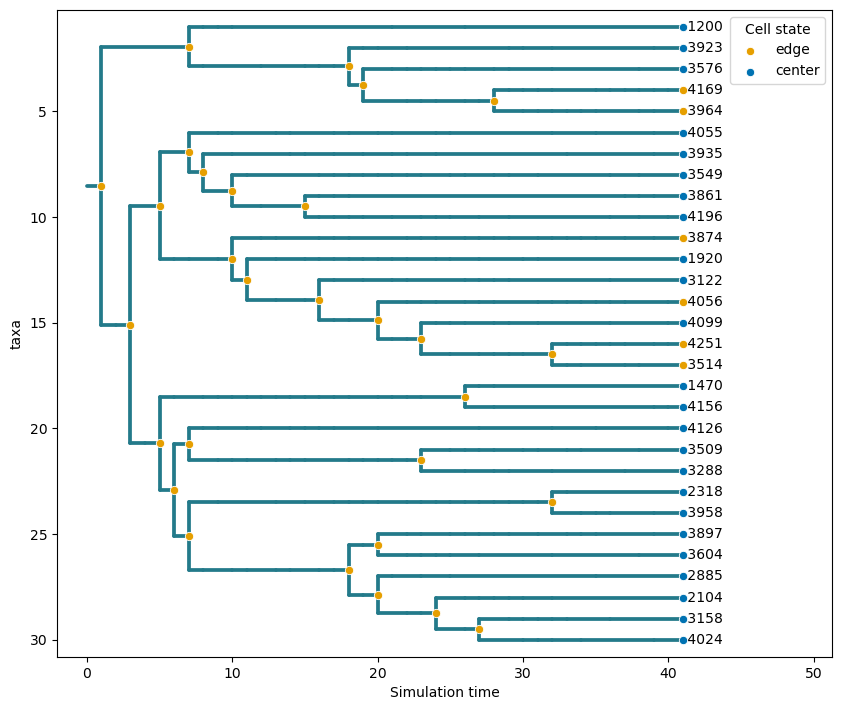

In [4]:
plot_tree = to_biopython_tree(tree)
fig, ax = plot_sim_tree(plot_tree, df)
ax.set_xlabel("Simulation time" if BRANCH_LENGTH == "time" else "Generation")
n_tips = plot_tree.count_terminals()
plt.show()

In [5]:
n_tips

30